
<font size=15 ><b> Instrumentos de deuda

</b></font>

# Cetes

Un Cete es un instrumento de **Deuda** a corto plazo, denominados en pesos mexicanos, emitidos por el gobierno Federal de Mexico, pertenecen a zero-coupon bonds, no realizan pagos periodicos de intereses, en cambio se adquieren a precio inferior a su valor nominal, y al vencimiento, el emisor se compromente a pagar dicho valor nominal.
| Característica	|CETES|
|   ----------------|-----|
|Emisor	|Gobierno Federal de México|
|Moneda|	Peso mexicano (MXN)|
|Valor nominal|	$10 MXN por título|
|Tipo de instrumento|	Bono cupón cero|
|Cupón|	0%|
|Plazos habituales	|28, 91, 182 y 364 días|
|Otros plazos	|Hasta 728 días, según emisiones disponibles|
|Convención de cálculo de rendimiento	|Días reales / 360|
|Pago|	Valor nominal al vencimiento||
|Colocación primaria	|Subastas mediante Banco de México|
|Mercado secundario	|Compraventa, entre otras operaciones|


Utilidad nominal a vencimineto es
$$ G = VN- P$$

El precio puede escrivirse como 
$$ P(t,T)= VN  * D(t,T)$$

$$\boxed {P = \frac{VN}{1+r\frac{d}{360}}} $$

despejando 
Y el factor de descuento queda:
$$
\boxed{D(t,T)=\frac{P(t,T)}{VN}=\frac{1}{1+r\frac{d}{360}}}
$$

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from datetime import date


def precio_cete(r, d, vn):
    """
    Precio a partir de la tasa anual simple de rendimiento.

    r : tasa en decimal (0.09 = 9%)
    d : días al vencimiento
    vn: valor nominal
    """
    if d < 0:
        raise ValueError("Los días no pueden ser negativos.")

    tau = d / 360
    denominador = 1 + r * tau

    if denominador <= 0:
        raise ValueError("Tasa fuera del dominio del modelo.")

    return vn / denominador

In [20]:
def dias_al_vencimiento(fecha_valuacion, fecha_vencimiento):
    """Días calendario reales entre dos fechas."""
    dias = (fecha_vencimiento - fecha_valuacion).days
    if dias < 0:
        raise ValueError("El CETE ya venció.")
    return dias

def rendimiento_cete(P, d, vn):
    """Tasa anual simple implícita en el precio."""
    if P <= 0 or d <= 0:
        raise ValueError("P y d deben ser positivos.")

    return (vn / P - 1) * 360/ d

In [23]:
import numpy as np
import matplotlib.pyplot as plt
from datetime import date





def factor_descuento(r, d, vn):
    """Factor de descuento del CETE."""
    return precio_cete(r, d, vn)/vn




Valor nominal:       $10.00
Plazo:                28 días
Tasa de rendimiento: 9.00%
Precio:              $9.930487
Ganancia nominal:    $0.069513
Rendimiento inverso: 9.0000%
Factor de descuento: 0.99304866


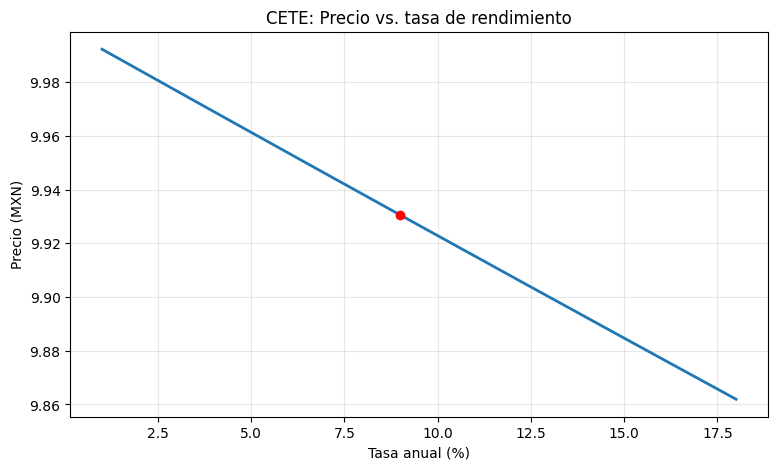

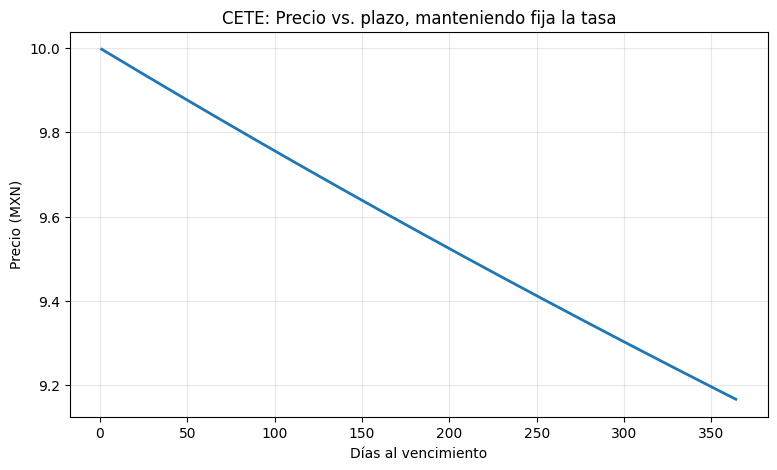

In [24]:
# Ejemplo hipotético: CETE de 28 días al 9% anual
vn = 10
r = 0.09
d = 28

P = precio_cete(r, d, vn)

print(f"Valor nominal:       ${vn:.2f}")
print(f"Plazo:                {d} días")
print(f"Tasa de rendimiento: {r:.2%}")
print(f"Precio:              ${P:.6f}")
print(f"Ganancia nominal:    ${vn-P:.6f}")
print(f"Rendimiento inverso: {rendimiento_cete(P,d,vn):.4%}")
print(f"Factor de descuento: {factor_descuento(r,d,vn):.8f}")


# Gráfica 1: Precio contra tasa de rendimiento

tasas = np.linspace(0.01, 0.18, 200)
precios = [precio_cete(tasa, d, vn) for tasa in tasas]

plt.figure(figsize=(9, 5))
plt.plot(tasas * 100, precios, linewidth=2)
plt.scatter([r * 100], [P], color="red", zorder=3)

plt.title("CETE: Precio vs. tasa de rendimiento")
plt.xlabel("Tasa anual (%)")
plt.ylabel("Precio (MXN)")
plt.grid(alpha=0.3)
plt.show()


# Gráfica 2: Precio contra plazo al vencimiento

plazos = np.arange(1, 365)
precios_plazo = [precio_cete(r, plazo, vn) for plazo in plazos]

plt.figure(figsize=(9, 5))
plt.plot(plazos, precios_plazo, linewidth=2)

plt.title("CETE: Precio vs. plazo, manteniendo fija la tasa")
plt.xlabel("Días al vencimiento")
plt.ylabel("Precio (MXN)")
plt.grid(alpha=0.3)
plt.show()




# Bonos M

Los Bonos de Desarrollo del Gobierno Federal con Tasa de Interés Fija, conocidos como Bonos M, son instrumentos de deuda soberana de mediano y largo plazo, denominados en pesos mexicanos, emitidos por el Gobierno Federal.

|Característica	|Bonos M|
|----|---------|
|Emisor|	Gobierno Federal
|Moneda|	MXN|
Valor |nominal	$100 MXN
Tasa cupón|	Fija
Periodicidad de cupones|	Cada 182 días, aproximadamente semestral
Convención de intereses	|Actual/360
Plazos de referencia	|3, 5, 10, 20 y 30 años
Amortización del principal|	Al vencimiento
Mercado	Primario y secundario

Los flujos contractuales desde la perspectiva del inversionista son:


\begin{cases}
C_j, & j<n\\
C_n+VN, & j=n
\end{cases}
En la fecha final, el flujo será:
$$
X_T=100+4.0444=104.0444
$$

In [28]:
# bonos M
def cupon(c, n, vn):
    tau = n/360
    return vn * c * tau

In [29]:
cupon(0.08, 182, 100)

4.044444444444444

In [37]:
def bonom(c, n, vn):
    tau = n/360
    return (vn + (cupon(c, n, vn)))

In [39]:
bonom(0.08, 728, 100)

116.17777777777778

# Udibonos


Bonos indexados a la inflacion
Los Bonos de Desarrollo del Gobierno Federal denominados en Unidades de Inversión (UDIBONOS) son instrumentos de deuda soberana emitidos por el Gobierno Federal de México, cuyo valor nominal está expresado en Unidades de Inversión (UDIs).

Son bonos de tasa real **fija** que pagan intereses periódicos y devuelven el principal al vencimiento.

|Característica	|UDIBONOS|
|-|-|
|Emisor|	Gobierno Federal de México|
Unidad de denominación	|UDI
Moneda de pago	|Peso mexicano (MXN)
Valor nominal	|100 UDIs
Tasa cupón	|Real y fija
Periodicidad de cupones|	Cada 182 días
Convención de intereses	|Días reales / 360
Plazos de referencia	|3, 5, 10 y 30 años, entre otros
Amortización	|Principal al vencimiento
Indexación	|Valor de la UDI, vinculado al INPC

¿Qué es una UDI?
La Unidad de Inversión (UDI) es una unidad de cuenta cuyo valor en pesos se actualiza conforme a las variaciones del Índice Nacional de Precios al Consumidor (INPC).

No es una moneda distinta del peso mexicano.

Denotamos por:
$$
U_t=\text{Valor en MXN de una UDI en la fecha }t

$$
Por ejemplo, supongamos que:

$$U_t=8.00\text{ MXN/UDI}
$$

Un valor nominal de 100 UDIs equivale a:

$$100(8.00)=800\text{ MXN}$$


El cupón expresado en UDIs es:

$$\boxed{C_j^{UDI}=VN\cdot c\cdot\frac{N_j}{360}}$$


Para obtener su pago en pesos:

$$\boxed{C_j^{MXN}=C_j^{UDI}\cdot U_{T_j}}$$


En la fecha de vencimiento \(T\), se paga también el principal:

$$\boxed{Principal_T^{MXN}=VN\cdot U_T}$$


Por tanto, los flujos contractuales en pesos son:

$$X_{T_j}^{MXN}=
\begin{cases}
C_j^{UDI}U_{T_j},&j<n\\[4pt]
(C_n^{UDI}+VN)U_T,&j=n
\end{cases}$$


In [40]:
import numpy as np
import matplotlib.pyplot as plt

def precio_udibono(vn, cupon, yield_real, n, udi, dias=182):
    """
    Valuación de UDIBONOS.

    Supuestos:
    - Valuación en fecha de pago de cupón.
    - Periodos regulares de 182 días.
    - Una sola tasa real de mercado (YTM).
    - Sin intereses devengados.

    vn         : Valor nominal en UDIs
    cupon      : Tasa cupón real anual
    yield_real : Rendimiento real anual de mercado
    n          : Número de cupones restantes
    udi        : Valor actual de la UDI en MXN
    dias       : Días por periodo
    """

    C = vn * cupon * dias / 360
    R = yield_real * dias / 360

    if n < 1 or int(n) != n:
        raise ValueError("n debe ser un entero positivo.")
    if 1 + R <= 0:
        raise ValueError("Rendimiento fuera del dominio.")

    # Valor presente de los cupones
    vp_cupones = sum(
        C / (1 + R)**j
        for j in range(1, n + 1)
    )

    # Valor presente del principal
    vp_nominal = vn / (1 + R)**n

    # Precio en UDIs
    precio_udi = vp_cupones + vp_nominal

    # Precio en pesos
    precio_mxn = precio_udi * udi

    return precio_udi, precio_mxn, vp_cupones, vp_nominal

VP cupones:   7.60246 UDIs
VP principal: 90.49692 UDIs
Precio:       98.09938 UDIs
Precio MXN:   $824.03


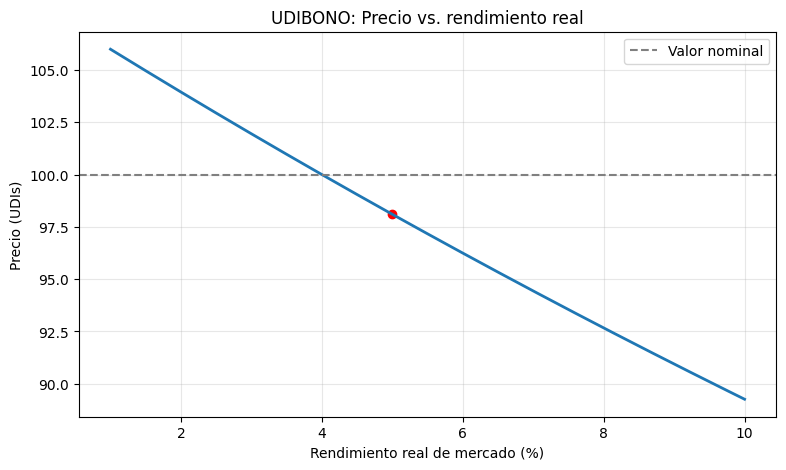

In [41]:
# Parámetros hipotéticos
VN = 100
cupon = 0.04
yield_real = 0.05
n = 4
udi = 8.40

p_udi, p_mxn, vp_c, vp_n = precio_udibono(
    VN, cupon, yield_real, n, udi
)

print(f"VP cupones:   {vp_c:.5f} UDIs")
print(f"VP principal: {vp_n:.5f} UDIs")
print(f"Precio:       {p_udi:.5f} UDIs")
print(f"Precio MXN:   ${p_mxn:.2f}")


# Precio ante diferentes tasas reales de mercado
tasas = np.linspace(0.01, 0.10, 200)

precios = [
    precio_udibono(VN, cupon, y, n, udi)[0]
    for y in tasas
]

plt.figure(figsize=(9, 5))

plt.plot(tasas * 100, precios, linewidth=2)
plt.axhline(VN, linestyle="--", color="gray",
            label="Valor nominal")

plt.scatter(yield_real * 100, p_udi, color="red")

plt.xlabel("Rendimiento real de mercado (%)")
plt.ylabel("Precio (UDIs)")
plt.title("UDIBONO: Precio vs. rendimiento real")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Repos

Una operación de reporto (repurchase agreement o repo) es una operación financiera en la que una parte vende temporalmente títulos de crédito a otra, comprometiéndose a recomprar títulos equivalentes en una fecha futura, a un precio previamente acordado.

En México, el artículo 259 de la Ley General de Títulos y Operaciones de Crédito establece que el reportador adquiere la propiedad de los títulos a cambio de dinero y se obliga a transferir títulos de la misma especie al reportado, a cambio del precio original más un premio.

El interés de la operación se denomina premio del reporto.

Para nuestro primer modelo utilizaremos interés simple, con una convención de días reales sobre 360:

$$\boxed{\Pi=M\cdot r_{\mathrm{repo}}\cdot\frac{d}{360}}
$$
Donde:
- $\Pi$: premio del reporto, en MXN.
- $M$: monto inicial de efectivo entregado.
- $r_{\mathrm{repo}}$: tasa de reporto anual expresada en decimal.
- $d$: días de duración de la operación.
- 360: base anual de cálculo.

El monto que el reportado debe entregar al vencimiento será:

$$\boxed{M_T=M+\Pi}$$


In [ ]:
def repo(vn, r, d):
    tau = d / 360
    premio = vn * r * tau
    return vn + premio


In [ ]:
# Ejemplo hipotético: repo de 7 días al 10% anual
repo(1000000, 0.1, 7)

1001944

# Bonos de tasa flotante

Un bono de tasa flotante (Floating Rate Note, FRN) es un instrumento de deuda cuyo cupón se determina mediante una tasa de interés variable, definida contractualmente a partir de una tasa de referencia de mercado.

La característica fundamental es que la tasa de interés cambia, pero el valor nominal del instrumento no necesariamente cambia.
|Características |generales|
|-|-|
Característica|	Bono de tasa flotante
Emisor	|Gobierno, banco o empresa
Valor nominal|	Definido contractualmente
Tasa cupón|	Variable
Tasa de referencia|	TIIE de Fondeo, SOFR u otra
Periodicidad de pago|	Según contrato
Amortización del principal|	Generalmente al vencimiento
Precio de mercado	|Variable
Moneda	|Según emisión

En su forma más general, la tasa aplicable a cada periodo puede expresarse como:

$$\boxed{R_j=L_j+s}
$$

Donde:
- \($R_j$\): tasa anual aplicable al periodo \(j\).
- \($L_j$\): tasa de referencia correspondiente al periodo.
- \($s$\): diferencial contractual fijo (spread), que puede ser cero.
Si la tasa se fija al inicio del periodo y los intereses se calculan mediante interés simple:

$$\boxed{C_j=VN(L_j+s)\frac{N_j}{360}}$$


Aquí \($C_j$\) es el cupón en pesos, \($VN$\) el valor nominal y \($N_j$\) los días del periodo.

# Caso Mexicano

## TIIE de Fondeo
La TIIE de Fondeo es una tasa de referencia calculada por Banco de México a partir de operaciones de fondeo al mayoreo en pesos, mediante reportos a un día hábil bancario con valores elegibles.

|Referencia|	Metodología|	¿Qué representa?|
|----------|---------------|-|
TIIE de Fondeo overnight|	Mediana ponderada por volumen de reportos elegibles	|Tasa observada del mercado de fondeo a un día hábil
TIIE a plazo para contratos legados|	Capitalización de la TIIE de Fondeo del día hábil anterior + diferencial histórico|	Referencia reconstruida para contratos anteriores a la transición
TIIE de Fondeo compuesta por adelantado	|Composición de tasas históricas observadas	|Tasa conocida al inicio del nuevo periodo de intereses
TIIE de Fondeo compuesta al vencimiento (in arrears)|	Capitalización de las tasas aplicables durante el periodo	|Remuneración acumulada en un periodo a tasa flotante

3. Definición matemática de la mediana ponderada
Sea la muestra de operaciones:

$$\mathcal S_t=\{(r_i,v_i)\}_{i=1}^{n}
$$

con:

$$r_i=\text{tasa repo anual de la operación }i
$$


$$v_i=\text{monto de efectivo de la operación }i
$$

Primero ordenamos las operaciones por tasa, de menor a mayor:

$$r_{(1)}\leq r_{(2)}\leq\cdots\leq r_{(n)}
$$

Si dos operaciones tienen la misma tasa, la metodología establece ordenar primero la operación de menor monto.

El volumen total es:
$$\boxed{V=\sum_{i=1}^{n}v_{(i)}}
$$

Para cada operación ordenada, calculamos la participación acumulada:

$$\boxed{
W_k=\frac{\sum_{i=1}^{k}v_{(i)}}{V}
}
$$

Definimos el primer índice para el cual se alcanza al menos el 50% del volumen:

$$\boxed{
k^*=\min\{k:W_k\geq0.5\}
}$$


Entonces la TIIE de Fondeo es:
\[
\boxed{
TF_t=r_{(k^*)}
}
\]

### Nueva metodología de las TIIE a plazo (contratos legados)

Un contrato legado (legacy contract) es un contrato financiero celebrado antes de una transición regulatoria, que continúa vigente bajo las condiciones pactadas originalmente.

Fórmula oficial

$$\boxed{
L_t^{(n)}
=
\left[
\left(
1+\frac{TF_{t-1}+A_t}{36000}
\right)^n-1
\right]\frac{36000}{n}+S
}
$$
Donde:

Donde:
|Variable|	Significado|
|-|-|
$L_t^{(n)}$	|TIIE a plazo de \(n\) días determinada en \(t\), expresada como porcentaje anual  
$TF_{t-1}$|	TIIE de Fondeo aplicable el día hábil anterior, en porcentaje anual
\(A_t\)	|Ajuste por cambio en la tasa objetivo aplicable en \(t\)
\(n\)	|28, 91 o 182 días
\(S\)	|Diferencial histórico de 24 puntos base, equivalente a 0.24 puntos porcentuales


### TIIE de Fondeo a 30 días — Tasa compuesta
Primero, una precisión importante: Banco de México no publica una TIIE de Fondeo Compuesta por Adelantado estandarizada a 30 días. Los plazos oficiales son 28, 91 y 182 días. Sin embargo, sí podemos calcular una TIIE de Fondeo compuesta para un periodo de 30 días naturales utilizando las tasas overnight o el índice de capitalización publicado por Banco de México